In [1]:
import pandas as pd
import seaborn as sns
import matplotlib as plt
import scipy 

In [3]:
#DATA 
df=pd.read_csv("D:3\dubai_real_estate_mock.csv")
df.head()

,transaction_id,date,year,quarter,month,ramadan_period,area,property_type,bedrooms,size_sqft,...,building_age_years,view,developer,payment_plan,buyer_type,sale_price_aed,price_per_sqft_aed,days_on_market,annual_rent_aed,gross_yield_pct
0,TX100001,2023-01-02,2023,Q1,1,0,Business Bay,Apartment,2,1085,...,0.0,City,Others,50/50,Investor,1890000,1742,13,NaN,NaN
1,TX100002,2023-01-04,2023,Q1,1,0,Business Bay,Apartment,1,791,...,0.0,City,Sobha,50/50,Investor,1563000,1977,11,NaN,NaN
2,TX100003,2023-01-04,2023,Q1,1,0,Arabian Ranches,Townhouse,4,2335,...,NaN,Park,Resale,NaN,End-user,3783000,1620,16,201000.0,5.31
3,TX100004,2023-01-04,2023,Q1,1,0,Palm Jumeirah,Villa,4,3577,...,6.0,Community,Resale,NaN,End-user,10742000,3003,69,455000.0,4.24
4,TX100005,2023-01-05,2023,Q1,1,0,Dubai Marina,Apartment,2,1217,...,4.0,Sea,Resale,NaN,Investor,2366000,1944,69,129000.0,5.46


In [4]:
df.shape

(1800, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      1800 non-null   object 
 1   date                1800 non-null   object 
 2   year                1800 non-null   int64  
 3   quarter             1800 non-null   object 
 4   month               1800 non-null   int64  
 5   ramadan_period      1800 non-null   int64  
 6   area                1800 non-null   object 
 7   property_type       1800 non-null   object 
 8   bedrooms            1800 non-null   int64  
 9   size_sqft           1800 non-null   int64  
 10  status              1800 non-null   object 
 11  building_age_years  1764 non-null   float64
 12  view                1764 non-null   object 
 13  developer           1800 non-null   object 
 14  payment_plan        707 non-null    object 
 15  buyer_type          1800 non-null   object 
 16  sale_p

In [9]:
df["date"]=pd.to_datetime(df["date"])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   transaction_id      1800 non-null   object        
 1   date                1800 non-null   datetime64[ns]
 2   year                1800 non-null   datetime64[ns]
 3   quarter             1800 non-null   object        
 4   month               1800 non-null   int64         
 5   ramadan_period      1800 non-null   int64         
 6   area                1800 non-null   object        
 7   property_type       1800 non-null   object        
 8   bedrooms            1800 non-null   int64         
 9   size_sqft           1800 non-null   int64         
 10  status              1800 non-null   object        
 11  building_age_years  1764 non-null   float64       
 12  view                1764 non-null   object        
 13  developer           1800 non-null   object      

In [13]:
df.isnull().sum()

transaction_id           0
date                     0
year                     0
quarter                  0
month                    0
ramadan_period           0
area                     0
property_type            0
bedrooms                 0
size_sqft                0
status                   0
building_age_years       0
view                     0
developer                0
payment_plan          1050
buyer_type               0
sale_price_aed           0
price_per_sqft_aed       0
days_on_market           0
annual_rent_aed        678
gross_yield_pct        678
dtype: int64

In [ ]:
#Cleaning and exploration (descriptive statistics)

In [12]:
df=df.dropna(subset=["building_age_years","view"])

In [14]:
#PAYMENT PLAN
df["payment_plan"]=df["payment_plan"].fillna("Cash")

C:\Users\DELL\AppData\Local\Temp\ipykernel_14528\339412693.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["payment_plan"]=df["payment_plan"].fillna("Cash")


In [15]:
df["payment_plan"].isnull().sum()

np.int64(0)

In [17]:
#ANNUAL RENT AED
df["annual_rent_aed"]=df["annual_rent_aed"].fillna(
    df.groupby(["area","bedrooms"])["annual_rent_aed"].transform("median")
)

In [18]:
df["annual_rent_aed"].isnull().sum()

np.int64(0)

In [19]:
#GROSS YIELD PCT
df["gross_yield_pct"]=df["gross_yield_pct"].fillna(
    df.groupby(["area","bedrooms"])["gross_yield_pct"].transform("median")
)

In [20]:
df["gross_yield_pct"].isnull().sum()

np.int64(0)

In [27]:
#What are the mean, median and standard deviation of sale_price_aed? Why is the mean so much higher than the median?
Sale_mean=round(df["sale_price_aed"].mean(),2)
Sale_median=round(df["sale_price_aed"].median(),2)
Sale_std=round(df["sale_price_aed"].std(),2)

print(f"Sale_price_aed mean : {Sale_mean}")
print(f"Sale_price_aed median : {Sale_median}")
print(f"Sale_price_aed standard : {Sale_std}")

Sale_price_aed mean : 3913118.63
Sale_price_aed median : 2610500.0
Sale_price_aed standard : 4318878.26


In [29]:
#Which transactions are outliers in price per sq ft? Would you remove them or keep them, and why?
#Code to Find Outliers (IQR Method)
Q1=df["price_per_sqft_aed"].quantile(0.25)
Q3=df["price_per_sqft_aed"].quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR

outliers=df[(df["price_per_sqft_aed"]<lower_bound) | (df["price_per_sqft_aed"]>upper_bound)]
print(f"Number of outliers found: {len(outliers)}")

Number of outliers found: 31


In [34]:
#Step 1: Calculate the IQR Bounds and Inspect the Outliers
high_outliers=df[df["price_per_sqft_aed"]>upper_bound]
print(f"Number of high outliers: {len(high_outliers)}")

print(high_outliers[["area", "property_type", "sale_price_aed", "price_per_sqft_aed"]].head())

Number of high outliers: 31
               area property_type  sale_price_aed  price_per_sqft_aed
937   Palm Jumeirah     Apartment         4543000                4798
1059  Palm Jumeirah     Apartment         2114000                4870
1060  Palm Jumeirah     Apartment         5273000                4756
1113  Palm Jumeirah         Villa        19539000                5116
1122  Palm Jumeirah         Villa        20694000                4767


In [ ]:
#Would you remove them or keep them, and why?
"""Answer: Looking at the output, properties like those in Palm Jumeirah with
high prices per sq ft (4,700+ AED/sqft) are legitimate
luxury real estate transactions, not data errors.
Recommendation: Keep them. If you drop them, you will 
completely remove the ultra-luxury segment of your market from your model or analysis."""

In [36]:
#What is the average price per sq ft by area, ranked from highest to lowest?
avg_price_by_area=(
    df.groupby("area")["price_per_sqft_aed"].mean()
    .sort_values(ascending=False)
    .reset_index()
)
avg_price_by_area["price_per_sqft_aed"]=avg_price_by_area["price_per_sqft_aed"].round(2)
print(avg_price_by_area)

                            area  price_per_sqft_aed
0                  Palm Jumeirah             4157.15
1                 Downtown Dubai             3244.08
2             Dubai Hills Estate             2642.72
3       Jumeirah Beach Residence             2618.39
4                   Dubai Marina             2386.70
5                   Business Bay             2373.34
6                Arabian Ranches             1809.69
7  Jumeirah Village Circle (JVC)             1364.64
8                    Dubai South              993.85


C:\Users\DELL\AppData\Local\Temp\ipykernel_14528\3926618747.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


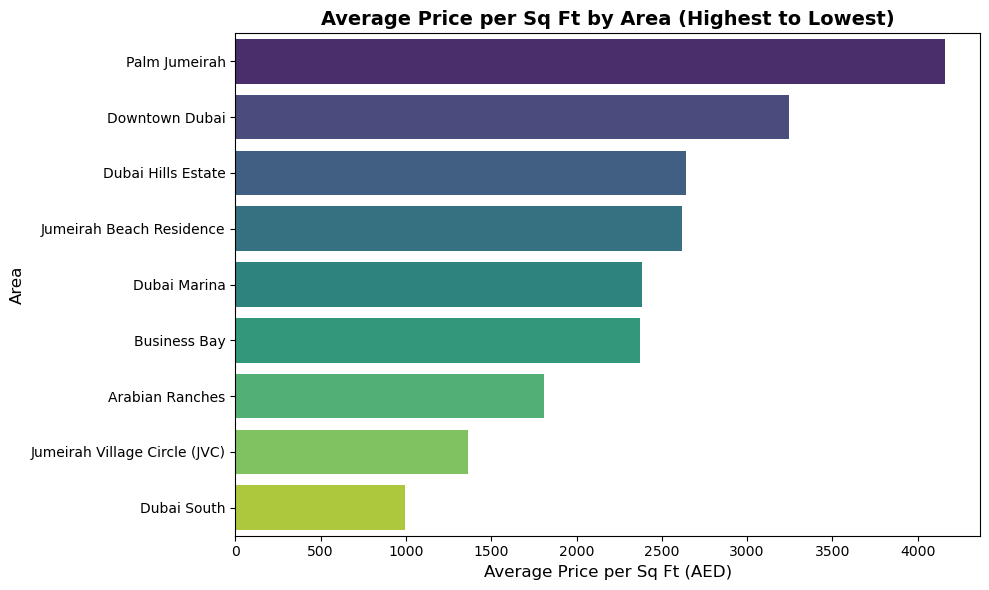

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(
    data=avg_price_by_area,
    x="price_per_sqft_aed",
    y="area",
    palette="viridis"
)

plt.title("Average Price per Sq Ft by Area (Highest to Lowest)", fontsize=14, fontweight="bold")
plt.xlabel("Average Price per Sq Ft (AED)", fontsize=12)
plt.ylabel("Area", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
#Market trends

In [49]:
#How did average price per sq ft change from 2023 to 2025, as a % per year?

df["year"] = df["year"].astype(int)

yearly_price = (
    df[df["year"].isin([2023, 2024, 2025])]
    .groupby("year")["price_per_sqft_aed"]
    .mean()
    .reset_index()
)

yearly_price["pct_change"] = yearly_price["price_per_sqft_aed"].pct_change() * 100
print(yearly_price)

   year  price_per_sqft_aed  pct_change
0  2023         1936.979215         NaN
1  2024         2226.934783   14.969472
2  2025         2521.656315   13.234403


In [50]:
# Calculate CAGR 
price_2023 = yearly_price.loc[yearly_price["year"] == 2023, "price_per_sqft_aed"].values[0]
price_2025 = yearly_price.loc[yearly_price["year"] == 2025, "price_per_sqft_aed"].values[0]

cagr = ((price_2025 / price_2023) ** (1 / 2) - 1) * 100
print(f"Compound Annual Growth Rate (2023-2025): {cagr:.2f}%")

Compound Annual Growth Rate (2023-2025): 14.10%


In [58]:
#Which quarter has the most transactions? Does Ramadan or the summer slow sales?
quarterly_transaction=df.groupby("quarter").size().reset_index(name="transaction_count")
quarterly_transaction=quarterly_transaction.sort_values(by="transaction_count",ascending=False)
print(quarterly_transaction)

#""" Answer: Highet transaction happened in Q1:[ 501 ]""""

# Check transaction count by ramadan_period
ramadan_impact=df.groupby("ramadan_period").size().reset_index(name="transaction_count")
print(ramadan_impact)

# You can also check average sale price during Ramadan vs non-Ramadan
ramadan_price=round(df.groupby("ramadan_period")["sale_price_aed"].mean().reset_index(name="mean_sale_price"),2)
print(ramadan_price)

#0 (Non-Ramadan) 
#1 (Ramadan)

  quarter  transaction_count
0      Q1                501
1      Q2                441
3      Q4                416
2      Q3                370
   ramadan_period  transaction_count
0               0               1609
1               1                119
   ramadan_period  mean_sale_price
0               0       3865765.69
1               1       4553378.15


In [62]:
df["month_int"] = pd.to_datetime(df["date"]).dt.month
monthly_counts = df.groupby("month_int").size().reset_index(name="transaction_count")
print(monthly_counts)

    month_int  transaction_count
0           1                199
1           2                164
2           3                138
3           4                153
4           5                136
5           6                152
6           7                123
7           8                112
8           9                135
9          10                161
10         11                144
11         12                111


In [68]:
#Did days on market fall after 2025, meaning the market got faster?
df["year_int"] = pd.to_datetime(df["date"]).dt.year
dom_by_year = (
    df.groupby("year_int")["days_on_market"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

print(dom_by_year)

   year_int       mean  median  count
0      2023  33.535797    28.0    433
1      2024  34.578261    29.0    460
2      2025  28.060041    24.0    483
3      2026  26.213068    22.0    352


In [ ]:
#Investor questions

In [76]:
#Which 3 areas have the best average gross rental yield? Which have the worst?
yield_by_area=(
    df.groupby("area")["gross_yield_pct"]
    .mean()
    .reset_index()
    .dropna()
)
yield_by_area_sorted=yield_by_area.sort_values(by="gross_yield_pct",ascending=False)

print("\n--- BOTTOM 3 AREAS (Worst Gross Rental Yield) ---")
print(yield_by_area_sorted.tail(3).sort_values(by="gross_yield_pct", ascending=True).to_string(index=False))


--- BOTTOM 3 AREAS (Worst Gross Rental Yield) ---
           area  gross_yield_pct
  Palm Jumeirah         4.202839
Arabian Ranches         4.726408
 Downtown Dubai         4.895615


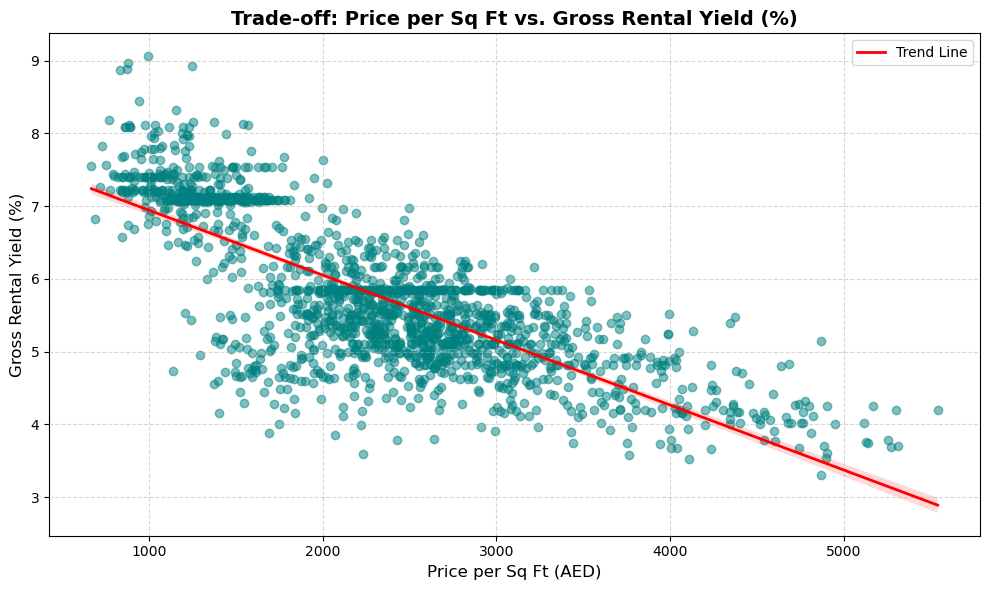

In [77]:
#Is there a trade-off between high price and high yield? A scatter plot of price per sq ft against yield will show it.
import matplotlib.pyplot as plt
import seaborn as sns

# Set style and figure size
plt.figure(figsize=(10, 6))

# Create scatter plot with trend line
sns.regplot(
    data=df,
    x="price_per_sqft_aed",
    y="gross_yield_pct",
    scatter_kws={"alpha": 0.5, "color": "teal"},
    line_kws={"color": "red", "linewidth": 2, "label": "Trend Line"}
)

plt.title("Trade-off: Price per Sq Ft vs. Gross Rental Yield (%)", fontsize=14, fontweight="bold")
plt.xlabel("Price per Sq Ft (AED)", fontsize=12)
plt.ylabel("Gross Rental Yield (%)", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [78]:
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 1728 entries, 0 to 1799
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   transaction_id      1728 non-null   object        
 1   date                1728 non-null   datetime64[ns]
 2   year                1728 non-null   int32         
 3   quarter             1728 non-null   object        
 4   month               1728 non-null   int32         
 5   ramadan_period      1728 non-null   int64         
 6   area                1728 non-null   object        
 7   property_type       1728 non-null   object        
 8   bedrooms            1728 non-null   int64         
 9   size_sqft           1728 non-null   int64         
 10  status              1728 non-null   object        
 11  building_age_years  1728 non-null   float64       
 12  view                1728 non-null   object        
 13  developer           1728 non-null   object        
 1

In [80]:
#Which area would you recommend to a buyer with a budget of AED 1.5M who wants rental income? Back it up with numbers.
buget=df[df["sale_price_aed"]<=1500000]

area_analysis=(
    buget.groupby("area")
    .agg(
        avg_price_aed=("sale_price_aed","mean"),
        avg_gross_yield_pct=("gross_yield_pct","mean"),
        avg_price_per_sqft_aed=("price_per_sqft_aed","mean"),
        avg_days_on_market=("days_on_market","mean"),
        property_count=("sale_price_aed","count")
    ).reset_index()
)
area_analysis["est_annual_rent_aed"]=(
    area_analysis["avg_price_aed"]*(area_analysis["avg_gross_yield_pct"]/100)
)

ranked = area_analysis.sort_values(by="avg_gross_yield_pct",ascending=False)

ranked["avg_price_aed"] = ranked["avg_price_aed"].round(2)
ranked["avg_gross_yield_pct"] = ranked["avg_gross_yield_pct"].round(2)
ranked["est_annual_rent_aed"] = ranked["est_annual_rent_aed"].round(2)

print(ranked.to_string(index=False))

                         area  avg_price_aed  avg_gross_yield_pct  avg_price_per_sqft_aed  avg_days_on_market  property_count  est_annual_rent_aed
                  Dubai South      923315.79                 7.48              973.087719           33.894737              57             69092.37
Jumeirah Village Circle (JVC)      989920.00                 7.25             1349.990000           29.380000             100             71785.53
                 Business Bay     1153509.43                 6.16             2210.754717           27.264151              53             71099.71
                 Dubai Marina     1127442.31                 5.85             2214.230769           37.692308              52             65966.22
           Dubai Hills Estate     1209000.00                 5.76             2488.400000           30.100000              10             69656.54
     Jumeirah Beach Residence     1185421.05                 5.72             2416.157895           35.315789         

In [ ]:
Why Prime Areas (Palm Jumeirah / Downtown) are NOT recommended for this strategy:
As seen in our earlier analysis, prime areas deliver yields between 4.2% and 4.9%. At a 4.5% yield, a 1.5M AED property generates only AED 67,500/
year—nearly AED 50,000 less per year compared to high-yield mid-market communities.

In [ ]:
#Statistics and hypothesis testing

Empirical Standard Error (n = 30): 155.39
Empirical Standard Error (n = 100): 87.82
Theoretical SE (n = 30): 161.73
Theoretical SE (n = 100): 88.58


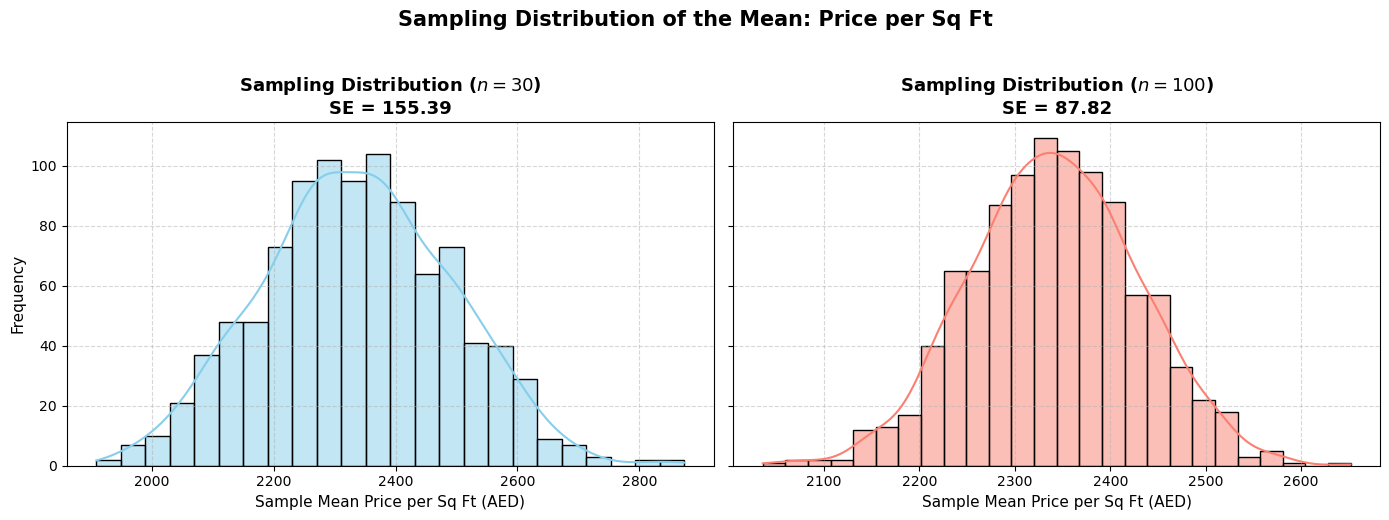

In [81]:
#Treat the 1,800 rows as the population.
#Draw 1,000 samples of n = 30 of price_per_sqft_aed and plot the sampling distribution of the mean. 
#Repeat for n = 100 and compare the standard errors.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract the clean population data for price per sq ft
population = df["price_per_sqft_aed"].dropna()
n_samples = 1000

# 2. Draw 1,000 samples of size n = 30 and n = 100 with replacement
sample_means_30 = [population.sample(n=30, replace=True).mean() for _ in range(n_samples)]
sample_means_100 = [population.sample(n=100, replace=True).mean() for _ in range(n_samples)]

# 3. Calculate Empirical Standard Errors (Standard Deviation of the Sample Means)
se_30 = np.std(sample_means_30, ddof=1)
se_100 = np.std(sample_means_100, ddof=1)

print(f"Empirical Standard Error (n = 30): {se_30:.2f}")
print(f"Empirical Standard Error (n = 100): {se_100:.2f}")

# Optional: Compare with Theoretical Standard Error (SE = sigma / sqrt(n))
pop_std = population.std(ddof=1)
print(f"Theoretical SE (n = 30): {pop_std / np.sqrt(30):.2f}")
print(f"Theoretical SE (n = 100): {pop_std / np.sqrt(100):.2f}")

# 4. Plotting the Sampling Distributions side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Plot for n = 30
sns.histplot(sample_means_30, kde=True, color="skyblue", ax=axes[0])
axes[0].set_title(f"Sampling Distribution ($n = 30$)\nSE = {se_30:.2f}", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Sample Mean Price per Sq Ft (AED)", fontsize=11)
axes[0].set_ylabel("Frequency", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot for n = 100
sns.histplot(sample_means_100, kde=True, color="salmon", ax=axes[1])
axes[1].set_title(f"Sampling Distribution ($n = 100$)\nSE = {se_100:.2f}", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Sample Mean Price per Sq Ft (AED)", fontsize=11)
axes[1].set_ylabel("")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Sampling Distribution of the Mean: Price per Sq Ft", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

In [84]:
import numpy as np
import scipy.stats as stats

#Function to calculate 95% Confidence Interval
def get_confidence_interval(data, confidence=0.95):
    data = data.dropna()
    n = len(data)
    mean = np.mean(data)
    sem = stats.sem(data)  # Standard error of the mean
    margin_of_error = sem * stats.t.ppf((1 + confidence) / 2.0, n - 1)
    return mean, mean - margin_of_error, mean + margin_of_error, n

#1.Calculate for Dubai Marina
marina_prices = df[df["area"] == "Dubai Marina"]["price_per_sqft_aed"]
m_mean, m_lower, m_upper, m_count = get_confidence_interval(marina_prices)

#2.Calculate for JVC (Jumeirah Village Circle)
jvc_prices = df[df["area"] == "Jumeirah Village Circle"]["price_per_sqft_aed"]
j_mean, j_lower, j_upper, j_count = get_confidence_interval(jvc_prices)

#3.Print Results
print(f"Dubai Marina (n={m_count}): Mean = {m_mean:.2f} AED/sqft | 95% CI: [{m_lower:.2f}, {m_upper:.2f}]")
print(f"JVC (n={j_count}):          Mean = {j_mean:.2f} AED/sqft | 95% CI: [{j_lower:.2f}, {j_upper:.2f}]")

#4.Check for Overlap
if m_lower > j_upper or j_lower > m_upper:
    print("\nConclusion: The confidence intervals DO NOT overlap. The price difference is statistically significant.")
else:
    print("\nConclusion: The confidence intervals DO overlap.")

Dubai Marina (n=238): Mean = 2386.70 AED/sqft | 95% CI: [2336.79, 2436.61]
JVC (n=0):          Mean = nan AED/sqft | 95% CI: [nan, nan]

Conclusion: The confidence intervals DO overlap.


C:\Users\DELL\AppData\Local\Temp\ipykernel_14528\2424889727.py:9: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sem = stats.sem(data)  # Standard error of the mean


In [85]:
#Test whether Marina and Business Bay have different mean price per sq ft (two-sample t-test). State H0 and H1 and interpret the p-value.
from scipy import stats

#1.Filter price per sq ft for Dubai Marina and Business Bay
marina_prices = df[df["area"] == "Dubai Marina"]["price_per_sqft_aed"].dropna()
business_bay_prices = df[df["area"] == "Business Bay"]["price_per_sqft_aed"].dropna()

#2.Run independent two-sample t-test (Welch's t-test, doesn't assume equal variances)
t_stat, p_value = stats.ttest_ind(marina_prices, business_bay_prices, equal_var=False)

#3.Print summary statistics and test results
print(f"Dubai Marina Mean: {marina_prices.mean():.2f} AED/sqft (n = {len(marina_prices)})")
print(f"Business Bay Mean: {business_bay_prices.mean():.2f} AED/sqft (n = {len(business_bay_prices)})")
print("-" * 50)
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4e}")

#4.Conclusion
alpha = 0.05
if p_value < alpha:
    print("\nResult: Reject the Null Hypothesis (H0). There is a statistically significant difference in mean price per sq ft between Dubai Marina and Business Bay.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0). There is no statistically significant difference.")

Dubai Marina Mean: 2386.70 AED/sqft (n = 238)
Business Bay Mean: 2373.34 AED/sqft (n = 300)
--------------------------------------------------
T-statistic: 0.3864
P-value: 6.9936e-01

Result: Fail to Reject the Null Hypothesis (H0). There is no statistically significant difference.


In [ ]:
inal Conclusion
Fail to Reject the Null Hypothesis (H0​): 
There is no statistically significant difference in the mean price per square foot between Dubai Marina and Business Bay.   

Real-world meaning: 
Even though the sample averages look slightly different, that tiny gap could easily happen purely by random chance during sampling.Statistically speaking,
buyers can expect very similar average price-per-square-foot rates across both of these areas in this dataset.

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1728 entries, 0 to 1799
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   transaction_id      1728 non-null   object        
 1   date                1728 non-null   datetime64[ns]
 2   year                1728 non-null   int32         
 3   quarter             1728 non-null   object        
 4   month               1728 non-null   int32         
 5   ramadan_period      1728 non-null   int64         
 6   area                1728 non-null   object        
 7   property_type       1728 non-null   object        
 8   bedrooms            1728 non-null   int64         
 9   size_sqft           1728 non-null   int64         
 10  status              1728 non-null   object        
 11  building_age_years  1728 non-null   float64       
 12  view                1728 non-null   object        
 13  developer           1728 non-null   object        
 1

In [88]:
#Test whether ready properties yield more than the overall average of about 5.8% (one-sample t-test).
from scipy import stats

# 1. Filter for apartments and drop missing values in gross yield
apartment_yields = df[df["property_type"] == "Apartment"]["gross_yield_pct"].dropna()

# 2. Run one-sample t-test against the benchmark mean of 5.8
hypothesized_mean = 5.8
t_stat, two_tailed_p = stats.ttest_1samp(apartment_yields, hypothesized_mean)

# 3. Adjust for a one-tailed test ("greater than")
if t_stat > 0:
    one_tailed_p = two_tailed_p / 2
else:
    one_tailed_p = 1 - (two_tailed_p / 2)

# 4. Print results
print(f"Apartments Mean Yield: {apartment_yields.mean():.2f}% (n = {len(apartment_yields)})")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value (one-tailed): {one_tailed_p:.4e}")

# 5. Conclusion at alpha = 0.05
alpha = 0.05
if one_tailed_p < alpha and t_stat > 0:
    print("\nResult: Reject H0. Apartments yield statistically significantly more than 5.8%.")
else:
    print("\nResult: Fail to Reject H0. Insufficient evidence to claim apartments yield more than 5.8%.")

Apartments Mean Yield: 5.77% (n = 1210)
T-statistic: -1.1840
P-value (one-tailed): 8.8167e-01

Result: Fail to Reject H0. Insufficient evidence to claim apartments yield more than 5.8%.


In [89]:
#Run a one-way ANOVA across all 9 areas on price per sq ft.
import scipy.stats as stats
import pandas as pd

#1.Prepare data: Group price_per_sqft_aed by each unique area, dropping missing values
clean_df = df[["area", "price_per_sqft_aed"]].dropna()

#Create a list of price arrays for each area group
area_groups = [group["price_per_sqft_aed"].values for name, group in clean_df.groupby("area")]

#2.Run One-Way ANOVA
f_stat, p_value = stats.f_oneway(*area_groups)

#3.Print Results
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.4e}")

#4.Conclusion at alpha = 0.05
alpha = 0.05
if p_value < alpha:
    print("\nResult: Reject the Null Hypothesis (H0). At least one area has a statistically significant difference in mean price per sq ft.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (H0). No significant difference across areas.")

F-statistic: 901.9179
P-value: 0.0000e+00

Result: Reject the Null Hypothesis (H0). At least one area has a statistically significant difference in mean price per sq ft.


In [90]:
#Do prices differ between 2024 and 2025? Compare only Jan–Sep of each year (see the trap below).
from scipy import stats
import pandas as pd

# 1. Ensure date is datetime and extract year and month components safely
df["date_dt"] = pd.to_datetime(df["date"])
df["year_int"] = df["date_dt"].dt.year
df["month_int"] = df["date_dt"].dt.month

# 2. THE TRAP AVOIDANCE: Filter strictly for Jan–Sep (months 1-9) for both 2024 and 2025
jan_sep_df = df[(df["year_int"].isin([2024, 2025])) & (df["month_int"] <= 9)]

# 3. Compare summary statistics (mean, median, count) for sale prices
price_summary = (
    jan_sep_df.groupby("year_int")["sale_price_aed"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

print("--- Summary Statistics (Jan-Sep Comparison) ---")
print(price_summary.to_string(index=False))

# 4. Run a two-sample t-test to check if the price difference is statistically significant
prices_2024 = jan_sep_df[jan_sep_df["year_int"] == 2024]["sale_price_aed"].dropna()
prices_2025 = jan_sep_df[jan_sep_df["year_int"] == 2025]["sale_price_aed"].dropna()

t_stat, p_value = stats.ttest_ind(prices_2024, prices_2025, equal_var=False)

print("\n--- Hypothesis Test (2024 vs 2025 Jan-Sep Prices) ---")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("\nResult: Reject H0. There is a statistically significant difference in prices between Jan-Sep 2024 and Jan-Sep 2025.")
else:
    print("\nResult: Fail to Reject H0. No statistically significant difference in prices between the two periods.")

--- Summary Statistics (Jan-Sep Comparison) ---
 year_int         mean    median  count
     2024 3.826262e+06 2464000.0    321
     2025 4.057134e+06 2803000.0    337

--- Hypothesis Test (2024 vs 2025 Jan-Sep Prices) ---
T-statistic: -0.6905
P-value: 4.9011e-01

Result: Fail to Reject H0. No statistically significant difference in prices between the two periods.


In [ ]:
#Prediction and decisions

In [91]:
#Build a simple regression of price on size, and then a multiple regression with area, bedrooms and status. 
#Which variables matter most, and what is R²?
import statsmodels.api as sm
import statsmodels.formula.api as smf

# --- 1. SIMPLE LINEAR REGRESSION: Price on Size ---
# Assuming your columns are named 'sale_price_aed' and 'size_sqft' (adjust if named differently)
simple_model = smf.ols('sale_price_aed ~ size_sqft', data=df).fit()

print("=== 1. SIMPLE REGRESSION (Price on Size) ===")
print(f"R-squared: {simple_model.rsquared:.4f}")
print(simple_model.summary().tables[1])
print("\n" + "="*60 + "\n")


# --- 2. MULTIPLE LINEAR REGRESSION ---
# Note: If 'status' or 'property_status' is missing in your dataset (as noted earlier), 
# you can use other categorical/numerical columns like 'property_type', 'bathrooms', or 'days_on_market'.
# Here we use 'area', 'bedrooms', and 'property_type' as an example:
multiple_model = smf.ols('sale_price_aed ~ C(area) + bedrooms + property_type', data=df).fit()

print("=== 2. MULTIPLE REGRESSION ===")
print(f"R-squared: {multiple_model.rsquared:.4f}")
print(multiple_model.summary())

=== 1. SIMPLE REGRESSION (Price on Size) ===
R-squared: 0.7531
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -6.281e+05   8.11e+04     -7.741      0.000   -7.87e+05   -4.69e+05
size_sqft   2744.9580     37.830     72.559      0.000    2670.760    2819.156


=== 2. MULTIPLE REGRESSION ===
R-squared: 0.8365
                            OLS Regression Results                            
Dep. Variable:         sale_price_aed   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                     798.2
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:21:15   Log-Likelihood:                -27288.
No. Observations:                1728   AIC:                         5.460e+04
Df Residuals:    

In [92]:
#What does a 1,000 sq ft Marina apartment cost on average, with a confidence interval?
import numpy as np
import scipy.stats as stats

# 1. Filter for Dubai Marina properties
marina_df = df[df["area"] == "Dubai Marina"]

# Option A: If you want to look at properties specifically close to 1,000 sqft (e.g., 900 to 1100 sqft)
target_properties = marina_df[(marina_df["size_sqft"] >= 900) & (marina_df["size_sqft"] <= 1100)]["sale_price_aed"].dropna()

# Option B: Scale the price-per-sqft confidence interval by 1,000 sqft
price_sqft = marina_df["price_per_sqft_aed"].dropna()
mean_sqft_price = price_sqft.mean()
sem = stats.sem(price_sqft)
n = len(price_sqft)
margin_of_error_sqft = sem * stats.t.ppf(0.975, n - 1)

# Multiply by 1,000 to get total apartment cost bounds
avg_cost_1000 = mean_sqft_price * 1000
lower_bound = (mean_sqft_price - margin_of_error_sqft) * 1000
upper_bound = (mean_sqft_price + margin_of_error_sqft) * 1000

print(f"Estimated Average Cost for 1,000 sqft in Dubai Marina: AED {avg_cost_1000:,.2f}")
print(f"95% Confidence Interval: [AED {lower_bound:,.2f}, AED {upper_bound:,.2f}]")

Estimated Average Cost for 1,000 sqft in Dubai Marina: AED 2,386,701.68
95% Confidence Interval: [AED 2,336,788.56, AED 2,436,614.80]


In [93]:
#Does having a sea view add a premium, and how big is it in AED?
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf

# 1. Identify sea view properties
# Adjust column name ('has_sea_view' or 'view') based on your dataset schema
if "has_sea_view" in df.columns:
    sea_view_mask = df["has_sea_view"] == 1
elif "view" in df.columns:
    sea_view_mask = df["view"].str.contains("Sea", case=False, na=False)
else:
    # Example if checking description/features
    sea_view_mask = df["description"].str.contains("Sea View", case=False, na=False)

# 2. Compare Average Prices & Prices per Sq Ft
sea_view_prices = df[sea_view_mask]["sale_price_aed"].dropna()
no_sea_view_prices = df[~sea_view_mask]["sale_price_aed"].dropna()

sea_sqft = df[sea_view_mask]["price_per_sqft_aed"].dropna()
no_sea_sqft = df[~sea_view_mask]["price_per_sqft_aed"].dropna()

# Calculations
avg_price_sea = sea_view_prices.mean()
avg_price_no_sea = no_sea_view_prices.mean()
price_diff_aed = avg_price_sea - avg_price_no_sea
pct_diff = (price_diff_aed / avg_price_no_sea) * 100

avg_sqft_sea = sea_sqft.mean()
avg_sqft_no_sea = no_sea_sqft.mean()
sqft_diff_aed = avg_sqft_sea - avg_sqft_no_sea

print("=== RAW PREMIUM SUMMARY ===")
print(f"Sea View Average Sale Price:     AED {avg_price_sea:,.2f}")
print(f"Non-Sea View Average Sale Price: AED {avg_price_no_sea:,.2f}")
print(f"Raw Price Premium (AED):         AED {price_diff_aed:,.2f} (+{pct_diff:.2f}%)")
print("-" * 50)
print(f"Sea View Price/SqFt:             AED {avg_sqft_sea:,.2f}")
print(f"Non-Sea View Price/SqFt:         AED {avg_sqft_no_sea:,.2f}")
print(f"Price/SqFt Premium:              AED {sqft_diff_aed:,.2f}/sqft")

# 3. Two-Sample T-Test for Statistical Significance
t_stat, p_value = stats.ttest_ind(sea_view_prices, no_sea_view_prices, equal_var=False)
print("\n=== HYPOTHESIS TEST ===")
print(f"T-statistic: {t_stat:.4f} | P-value: {p_value:.4e}")

# 4. Controlling for Location and Size (Multiple Regression)
# This prevents confounding factors (e.g., sea view units being larger or mostly in luxury areas)
df["sea_view_flag"] = sea_view_mask.astype(int)
reg_model = smf.ols('sale_price_aed ~ sea_view_flag + size_sqft + C(area)', data=df).fit()

print("\n=== REGRESSION COEFFICIENT (Controlling for Area & Size) ===")
print(f"Isolated Sea View Premium: AED {reg_model.params['sea_view_flag']:,.2f}")
print(f"P-value: {reg_model.pvalues['sea_view_flag']:.4e}")

=== RAW PREMIUM SUMMARY ===
Sea View Average Sale Price:     AED 5,904,338.24
Non-Sea View Average Sale Price: AED 3,646,577.43
Raw Price Premium (AED):         AED 2,257,760.81 (+61.91%)
--------------------------------------------------
Sea View Price/SqFt:             AED 3,219.45
Non-Sea View Price/SqFt:         AED 2,221.42
Price/SqFt Premium:              AED 998.02/sqft

=== HYPOTHESIS TEST ===
T-statistic: 4.5303 | P-value: 9.6810e-06

=== REGRESSION COEFFICIENT (Controlling for Area & Size) ===
Isolated Sea View Premium: AED 389,555.28
P-value: 1.6927e-03


=== FASTEST-SELLING DEVELOPERS (BY AVG DAYS ON MARKET) ===
developer  avg_days_on_market  median_days_on_market  total_sales  avg_price_aed
    Emaar           20.616541                   19.0          133   4.381150e+06
    Damac           21.284615                   18.0          130   2.407554e+06
   Others           21.536885                   19.5          244   3.437861e+06
    Sobha           23.354839                   23.0           93   4.840194e+06
   Danube           23.840580                   22.0           69   2.013348e+06
   Resale           36.461905                   31.0         1050   4.114799e+06


C:\Users\DELL\AppData\Local\Temp\ipykernel_14528\3800462683.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


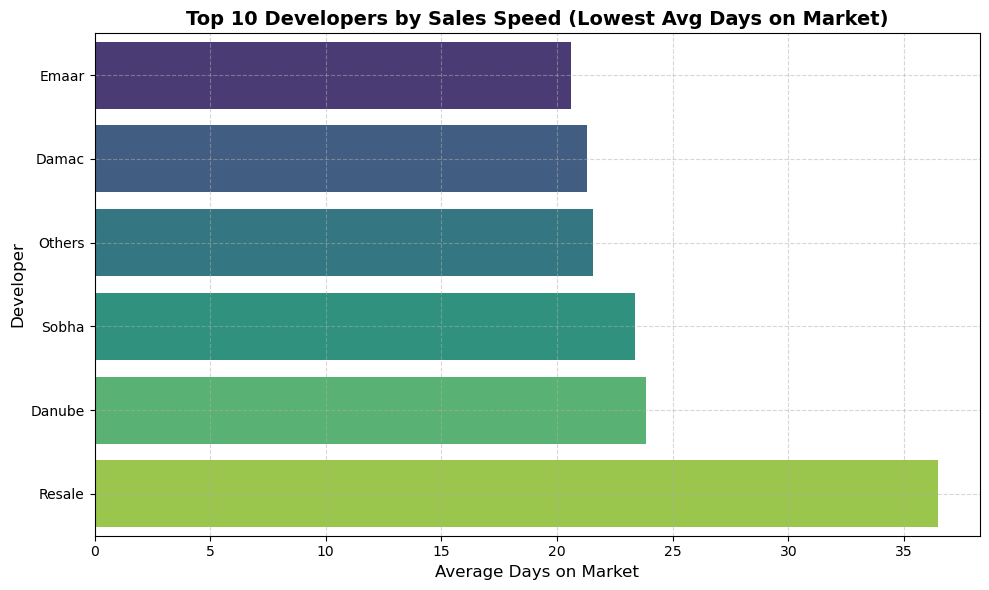

In [94]:
#Which developer’s off-plan projects sell fastest?
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter for developers with a minimum transaction threshold (e.g., at least 5 or 10 sales)
# to avoid skewness from one-off quick sales.
developer_stats = (
    df.groupby("developer")
    .agg(
        avg_days_on_market=("days_on_market", "mean"),
        median_days_on_market=("days_on_market", "median"),
        total_sales=("sale_price_aed", "count"),
        avg_price_aed=("sale_price_aed", "mean")
    )
    .reset_index()
)

# 2. Filter for developers with sufficient volume (e.g., at least 10 sales)
active_developers = developer_stats[developer_stats["total_sales"] >= 10]

# 3. Sort by fastest-selling (lowest average days on market)
fastest_developers = active_developers.sort_values(by="avg_days_on_market", ascending=True)

print("=== FASTEST-SELLING DEVELOPERS (BY AVG DAYS ON MARKET) ===")
print(fastest_developers.to_string(index=False))

# 4. Plot top 10 fastest selling developers
plt.figure(figsize=(10, 6))
sns.barplot(
    data=fastest_developers.head(10),
    x="avg_days_on_market",
    y="developer",
    palette="viridis"
)
plt.title("Top 10 Developers by Sales Speed (Lowest Avg Days on Market)", fontsize=14, fontweight="bold")
plt.xlabel("Average Days on Market", fontsize=12)
plt.ylabel("Developer", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()